In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages



### defining format

In [2]:
class State(TypedDict):
    # messages have the type "list". The add_messages funtion
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwritting them)
    messages : Annotated[list,add_messages]


In [3]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [4]:
from langchain_groq import ChatGroq
llm=ChatGroq(model="openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000020626EF0440>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000020626EF1160>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

### defining node defination

In [5]:
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

### adding node and edge to stategraph

In [6]:
graph_builder=StateGraph(State)
# creating node
graph_builder.add_node("llmchatbot",chatbot)
# adding edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot",END)

graph=graph_builder.compile()

#### visualization of graph

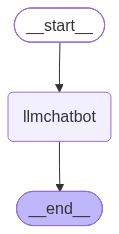

In [7]:
graph


In [8]:
response=graph.invoke({"messages": "Hi"})
response["messages"][-1].content

'Hello! How can I help you today?'

## Chatbot with tool

In [9]:
from langchain_tavily import TavilySearch
tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

schema of custom tool funciton

In [10]:
# @Tool
def fucntion(a:int , b:int)-> int:
    """ summary
    Args
        a : int __description__
        b : int __description__
    return
        r : int 
    """
    return a+b


In [14]:

def addition(a:int , b:int)-> int:
    """ summary
    Args
        a : int first number
        b : int second number
    return
        r : int result
    """
    return a+b

In [ ]:
Tools=[tool,addition]
